# Abdelhafidh Mahouel Notebook
# P2: Text Preprocessing - Manufacturing Continuous Improvement

- Author: [Abdelhafidh Mahouel](https://github.com/AbdelhafidhMahouel/)
- Repository: [nlp-02-text-preprocessing](https://github.com/AbdelhafidhMahouel/nlp-02-text-preprocessing/)
- Purpose: Apply text preprocessing to production shift notes and make deliberate cleaning decisions for manufacturing text
- Date: 2026-11

**Analytical question:** Which equipment problems and improvement themes appear most often
in production shift notes, and which preprocessing rules keep the manufacturing meaning intact?

**Data:** [data/production_log.txt](https://github.com/AbdelhafidhMahouel/nlp-02-text-preprocessing/blob/main/data/production_log.txt) contains 16 short
production log entries (one per line) covering downtime, defects, changeovers, maintenance, and kaizen ideas.
The entries are sample text written for this project with AI assistance and reviewed by me,
modeled on the kind of notes a process engineer reads in a shift handover or downtime log.
They do not come from a real plant.

## Section 1. Setup and Imports

In [1]:
# Section 1 Python cell.

# Imports at the top of the file
# REQ: External packages must be defined in pyproject.toml
# REQ: External packages must be installed in the environment using `uv sync` command
# REQ: External packages used in this notebook must be imported here

from collections import Counter
from itertools import pairwise
from pathlib import Path
import re

import matplotlib.pyplot as plt
import polars as pl

print("Imports complete.")

Imports complete.


## Section 2. Read the Production Log

In [2]:
# Section 2 Python cell

# In notebooks, start with the current working directory
# where the notebook is located.
NOTEBOOKS_PATH: Path = Path.cwd()
ROOT_PATH: Path = NOTEBOOKS_PATH.parent

DATA_PATH: Path = ROOT_PATH / "data"
NOTEBOOKS_PATH: Path = ROOT_PATH / "notebooks"
SCRIPTS_PATH: Path = ROOT_PATH / "scripts"

# Choose a text file to analyze.
# Each line is treated as one text record.
input_path: Path = DATA_PATH / "production_log.txt"

# Read all lines from the file.
text_list: list[str] = input_path.read_text(encoding="utf-8").splitlines()

# Remove blank lines.
text_list = [line.strip() for line in text_list if line.strip()]

print("Data loaded successfully.")
print(f"Loaded {len(text_list):,} text records.")

# Combine all text rows into one large string for simple preprocessing.
raw_text: str = " ".join(text_list)

print(f"Raw text length: {len(raw_text):,} characters")
print("First 500 characters of raw text:")
print(raw_text[:500])

Data loaded successfully.
Loaded 16 text records.
Raw text length: 1,251 characters
First 500 characters of raw text:
Line 2 stopped for 45 minutes because the conveyor belt jammed at station 3. CNC machine 4 produced 12 parts out of tolerance; tool wear on the cutting insert was the root cause. Changeover on the filling line took 90 minutes, well above the 30 minute SMED target. Hydraulic press leaked oil again; PM was not done last week. Operator found missing labels on 40 boxes because the label printer ran out of ribbon. Kaizen idea: add a shadow board so tools are not lost during changeover. A sensor fault


## Section 3. Inspect the Raw Text

Before cleaning, look for features that generic rules might damage:
abbreviations (*PM*, *QC*, *5S*, *OEE*, *PLC*, *CNC*), numbers and units (*45 minutes*, *62%*),
negations (*not done*, *No defects*), and hyphenated terms (*Poka-yoke*).

In [3]:
for i, line in enumerate(text_list, start=1):
    print(f"{i:>2}. {line}")

 1. Line 2 stopped for 45 minutes because the conveyor belt jammed at station 3.
 2. CNC machine 4 produced 12 parts out of tolerance; tool wear on the cutting insert was the root cause.
 3. Changeover on the filling line took 90 minutes, well above the 30 minute SMED target.
 4. Hydraulic press leaked oil again; PM was not done last week.
 5. Operator found missing labels on 40 boxes because the label printer ran out of ribbon.
 6. Kaizen idea: add a shadow board so tools are not lost during changeover.
 7. A sensor fault on the PLC stopped the packaging robot three times this shift.
 8. Scrap rate rose to 6% after a new resin lot; QC is checking the material.
 9. The 5S audit score dropped because walkways were blocked by pallets.
10. Bearing overheated on the main motor; maintenance replaced it after 2 hours of downtime.
11. OEE for line 1 was 62% this week, mostly from minor stops and slow cycle time.
12. No defects found after the root cause fix on the welding fixture.
13. The cha

## Section 4. Tokenize, Lowercase, and Remove Punctuation

These steps are the same as the example.

In [4]:
raw_tokens: list[str] = raw_text.split()
count_of_raw_tokens: int = len(raw_tokens)

lower_text: str = raw_text.lower()
no_punct_text: str = re.sub(r"[^a-z0-9\s]", " ", lower_text)
tokens_no_punct: list[str] = no_punct_text.split()
count_of_tokens_no_punct: int = len(tokens_no_punct)

print("First 20 raw tokens:", raw_tokens[:20])
print("First 20 tokens after cleaning:", tokens_no_punct[:20])
print(
    f"Raw tokens: {count_of_raw_tokens}, after punctuation removal: {count_of_tokens_no_punct}"
)

First 20 raw tokens: ['Line', '2', 'stopped', 'for', '45', 'minutes', 'because', 'the', 'conveyor', 'belt', 'jammed', 'at', 'station', '3.', 'CNC', 'machine', '4', 'produced', '12', 'parts']
First 20 tokens after cleaning: ['line', '2', 'stopped', 'for', '45', 'minutes', 'because', 'the', 'conveyor', 'belt', 'jammed', 'at', 'station', '3', 'cnc', 'machine', '4', 'produced', '12', 'parts']
Raw tokens: 220, after punctuation removal: 221


## Section 5. Apply the Example Rules First

The example removes 27 stop words and drops every token with 2 or fewer characters.
Check what that length rule throws away in manufacturing text.

In [5]:
STOP_WORDS: set[str] = {
    "a",
    "an",
    "and",
    "are",
    "as",
    "at",
    "be",
    "but",
    "by",
    "for",
    "from",
    "has",
    "have",
    "in",
    "is",
    "it",
    "its",
    "of",
    "on",
    "or",
    "that",
    "the",
    "to",
    "was",
    "were",
    "will",
    "with",
}

example_tokens: list[str] = [
    t for t in tokens_no_punct if len(t) > 2 and t not in STOP_WORDS
]
dropped_short: list[str] = sorted(
    {t for t in tokens_no_punct if len(t) <= 2 and t not in STOP_WORDS}
)

print(f"Cleaned tokens with example rules: {len(example_tokens)}")
print("Short tokens removed by the length rule:", dropped_short)

Cleaned tokens with example rules: 146
Short tokens removed by the length rule: ['1', '12', '2', '20', '3', '30', '4', '40', '45', '5s', '6', '62', '8', '90', 'no', 'pm', 'qc', 'so']


## Section 6. Deliberate Cleaning Decisions for Manufacturing Text

1. **Keep short domain abbreviations.** *PM* (preventive maintenance), *QC* (quality control),
   and *5S* are meaningful even though they have 2 characters.
2. **Keep negations.** *No defects* and *PM was not done* mean the opposite without them.
3. **Remove context and filler words.** *line*, *shift*, *station*, and *week* appear across
   many logs but describe where or when, not what went wrong. *because*, *after*, *this*,
   and *found* are filler in this text.
4. **Set numbers aside.** Numbers like *45* or *62* are measurements, not themes, so they are
   kept in a separate list instead of the word frequencies.

In [6]:
DOMAIN_STOP_WORDS: set[str] = {
    "line",
    "shift",
    "station",
    "week",
    "because",
    "after",
    "this",
    "found",
    "so",
    "out",
}

KEEP_SHORT: set[str] = {"pm", "qc", "5s", "no"}


def is_number(token: str) -> bool:
    """Return True if the token is only digits."""
    return token.isdigit()


def clean_custom(tokens: list[str]) -> list[str]:
    """Apply the manufacturing cleaning rules to a list of tokens."""
    stop_words = STOP_WORDS | DOMAIN_STOP_WORDS
    return [
        t
        for t in tokens
        if (len(t) > 2 or t in KEEP_SHORT) and t not in stop_words and not is_number(t)
    ]


custom_tokens: list[str] = clean_custom(tokens_no_punct)
numbers: list[str] = [t for t in tokens_no_punct if is_number(t)]

print(f"Cleaned tokens with custom rules: {len(custom_tokens)}")
print("Abbreviations and negations kept:", sorted(KEEP_SHORT & set(custom_tokens)))
print("Numbers set aside as measurements:", numbers)

Cleaned tokens with custom rules: 130
Abbreviations and negations kept: ['5s', 'no', 'pm', 'qc']
Numbers set aside as measurements: ['2', '45', '3', '4', '12', '90', '30', '40', '6', '2', '1', '62', '20', '8', '2', '2']


## Section 7. Compare Raw and Cleaned Token Counts

In [7]:
summary_df: pl.DataFrame = pl.DataFrame(
    {
        "stage": [
            "raw tokens",
            "after punctuation removal",
            "example rules",
            "custom rules",
        ],
        "count": [
            count_of_raw_tokens,
            count_of_tokens_no_punct,
            len(example_tokens),
            len(custom_tokens),
        ],
    }
)
print(summary_df)

shape: (4, 2)
┌───────────────────────────┬───────┐
│ stage                     ┆ count │
│ ---                       ┆ ---   │
│ str                       ┆ i64   │
╞═══════════════════════════╪═══════╡
│ raw tokens                ┆ 220   │
│ after punctuation removal ┆ 221   │
│ example rules             ┆ 146   │
│ custom rules              ┆ 130   │
└───────────────────────────┴───────┘


## Section 8. Most Frequent Cleaned Tokens

In [8]:
def top_tokens(tokens: list[str], n: int = 14) -> pl.DataFrame:
    """Return the n most frequent tokens with their counts."""
    return (
        pl.DataFrame({"token": tokens})
        .group_by("token")
        .len()
        .sort(["len", "token"], descending=[True, False])
        .head(n)
    )


pl.Config.set_tbl_rows(20)

example_top: pl.DataFrame = top_tokens(example_tokens)
custom_top: pl.DataFrame = top_tokens(custom_tokens)

print("Top tokens with example rules:")
print(example_top)
print("Top tokens with custom rules:")
print(custom_top)

Top tokens with example rules:
shape: (14, 2)
┌────────────┬─────┐
│ token      ┆ len │
│ ---        ┆ --- │
│ str        ┆ u64 │
╞════════════╪═════╡
│ after      ┆ 3   │
│ because    ┆ 3   │
│ changeover ┆ 3   │
│ dropped    ┆ 3   │
│ line       ┆ 3   │
│ not        ┆ 3   │
│ stopped    ┆ 3   │
│ belt       ┆ 2   │
│ cause      ┆ 2   │
│ conveyor   ┆ 2   │
│ found      ┆ 2   │
│ minutes    ┆ 2   │
│ missing    ┆ 2   │
│ out        ┆ 2   │
└────────────┴─────┘
Top tokens with custom rules:
shape: (14, 2)
┌────────────┬─────┐
│ token      ┆ len │
│ ---        ┆ --- │
│ str        ┆ u64 │
╞════════════╪═════╡
│ changeover ┆ 3   │
│ dropped    ┆ 3   │
│ not        ┆ 3   │
│ stopped    ┆ 3   │
│ belt       ┆ 2   │
│ cause      ┆ 2   │
│ conveyor   ┆ 2   │
│ minutes    ┆ 2   │
│ missing    ┆ 2   │
│ parts      ┆ 2   │
│ pm         ┆ 2   │
│ root       ┆ 2   │
│ scrap      ┆ 2   │
│ sensor     ┆ 2   │
└────────────┴─────┘


## Section 9. Visualize

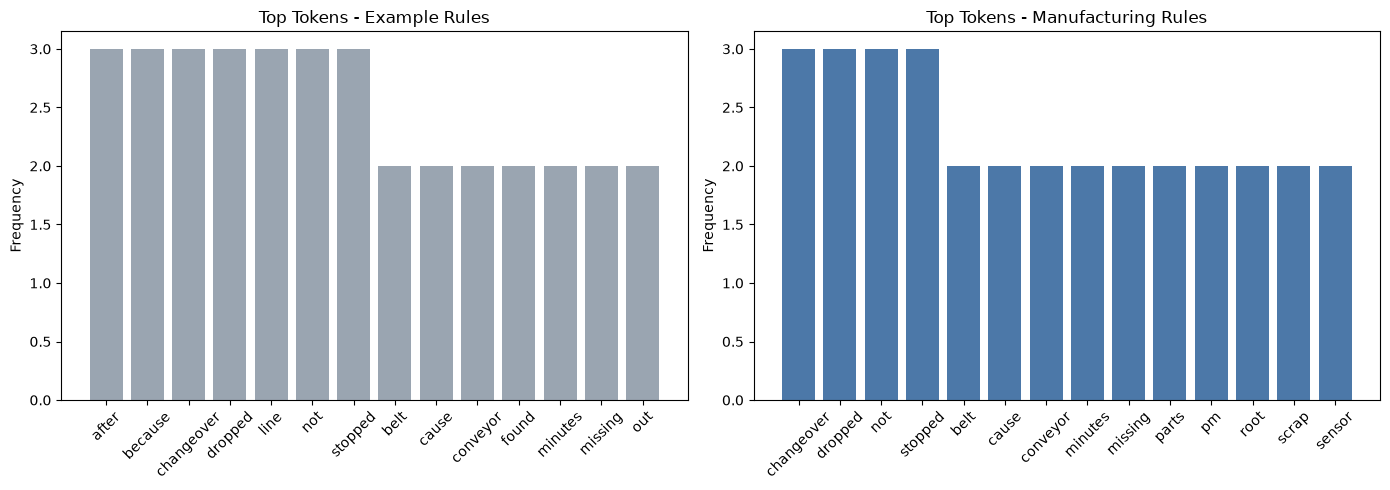

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(example_top["token"], example_top["len"], color="#9aa5b1")
axes[0].set_title("Top Tokens - Example Rules")
axes[0].set_ylabel("Frequency")
axes[0].tick_params(axis="x", labelrotation=45)

axes[1].bar(custom_top["token"], custom_top["len"], color="#4c78a8")
axes[1].set_title("Top Tokens - Manufacturing Rules")
axes[1].set_ylabel("Frequency")
axes[1].tick_params(axis="x", labelrotation=45)

plt.tight_layout()
plt.show()

## Section 10. Recurring Two-Word Phrases

Single words split engineering phrases like *root cause* and *conveyor belt*.
Counting adjacent pairs (bigrams) within each record shows phrases that repeat.

In [10]:
bigram_counts: Counter[str] = Counter()
for line in text_list:
    line_tokens = clean_custom(re.sub(r"[^a-z0-9\s]", " ", line.lower()).split())
    bigram_counts.update(f"{a} {b}" for a, b in pairwise(line_tokens))

print("Two-word phrases that appear more than once:")
for phrase, count in bigram_counts.most_common():
    if count > 1:
        print(f"- {phrase}: {count}")

Two-word phrases that appear more than once:
- conveyor belt: 2
- root cause: 2


## Section 11. Interpretation

**Counts.** The 16 log entries contain 220 raw tokens. Punctuation removal produced 221,
because *Poka-yoke* split into two tokens. The example rules kept 146 tokens and the
manufacturing rules kept 130.

**The example rules removed domain meaning.** The 2-character length rule silently dropped
*PM*, *QC*, *5S*, and *No*, plus every number. In manufacturing text these are not noise:
*PM was not done* is a maintenance finding and *No defects* confirms a fix worked.

**The custom rules surface process themes.** With the example rules, filler and context words
(*after*, *because*, *line*) were among the most frequent tokens. With the manufacturing rules,
the top tokens describe what happened: *changeover*, *stopped*, *dropped*, and *not* (3 each),
then *conveyor*, *belt*, *sensor*, *scrap*, *missing*, *parts*, *root*, and *cause* (2 each).
Changeovers, conveyor jams, sensor faults, and scrap are the recurring themes a continuous
improvement team would investigate first.

**Phrases matter.** Single-word counts split *root cause* and *conveyor belt*, which each
appear twice as two-word phrases. Bigrams are a better unit for engineering vocabulary.

**Ambiguity.** *pm* appears twice with two meanings: preventive maintenance (*PM was not done*)
and a clock time (*at 2 pm*). Lowercasing hides the difference, so a real project would map
abbreviations to full terms before counting.

**Information still lost.** Numbers were set aside, but they hold the key facts for this domain
(45 minutes of downtime, 62% OEE, 6% scrap). A next step would be to extract measurements with
their units as structured data instead of treating them as words.

**Conclusion.** Generic cleaning rules are a starting point, not a recipe. For manufacturing
text, keeping short abbreviations and negations, removing context words, and handling numbers
and phrases separately makes the frequency results much more useful for continuous improvement.